In [5]:
import sys
sys.path.append(r'/Users/kostastsampourakis/Desktop/code/Python/projects/gaussfiltax/gaussfiltax')

from flax import nnx  # type: ignore

import gc
import util.io
from util.plot import get_acf_plot
from functools import partial

import os
import time
import subprocess

from experiment_runner import ExperimentRunner
import experiment_descriptor as ed
import experiment_results as er
import jax.random as jr  # type: ignore
import misc

from util.numerics import log_prob_error, min_error, bias, get_num_sims
# from util.sample import sim_emissions, generate_emissions
# from util.train import find_mle, loglik_fn
# from inference.diagnostics.two_sample import sq_maximum_mean_discrepancy as mmd
import matplotlib.pyplot as plt  # type: ignore
import matplotlib_inline # type: ignore
import scienceplots # type: ignore

plt.style.use(['science', 'ieee'])
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

fig_dir = '/Users/kostastsampourakis/Desktop/code/Python/projects/gaussfiltax/figures'

/Users/kostastsampourakis/miniforge3/envs/jaxenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
runner = ExperimentRunner(exp_desc)

try:

    if os.path.exists(trial_dir):
        
        for root, _, files in os.walk(trial_dir, topdown=False):

            for name in files:

                os.remove(os.path.join(root, name))

        os.rmdir(trial_dir)

    key, subkey = jr.split(key)
    out = runner.run(trial=trial, plot_sims=True, key=subkey, seed=seed)

## Models and simulations

In [ ]:
# Parameters
state_dim = 4
state_noise_dim = 2
emission_dim = 2
emission_noise_dim = 2
seq_length = 30
mu0 = 1.0 * jnp.array([-0.05, 0.001, 0.7, -0.05])
q0 = jnp.zeros(state_noise_dim)
r0 = jnp.zeros(emission_noise_dim)
Sigma0 = 1.0 * jnp.array([[0.1, 0.0, 0.0, 0.0],[0.0, 0.005, 0.0, 0.0],[0.0, 0.0, 0.1, 0.0],[0.0, 0.0, 0.0, 0.01]])
Q = 1e-6 * jnp.eye(state_noise_dim)
R = 25*1e-6 * jnp.eye(emission_noise_dim)

dt = 0.5
FCV = jnp.array([[1, dt, 0, 0],[0, 1, 0, 0],[0, 0, 1, dt],[0, 0, 0, 1]])
acc = 0.5
Omega = lambda x, acc: 0.1 * acc / jnp.sqrt(x[1]**2 + x[3]**2)
FCT =  lambda x, a: jnp.array([[1, jnp.sin(dt * Omega(x, a)) / Omega(x, a), 0, -(1-jnp.cos(dt * Omega(x, a))) / Omega(x, a)],
                            [0, jnp.cos(dt * Omega(x, a)), 0, -jnp.sin(dt * Omega(x, a))],
                            [0, (1-jnp.cos(dt * Omega(x, a))) / Omega(x, a), 1, jnp.sin(dt * Omega(x, a)) / Omega(x, a)],
                            [0, jnp.sin(dt * Omega(x, a)), 0, jnp.cos(dt * Omega(x, a))]])

G = jnp.array([[0.5, 0],[1, 0],[0, 0.5],[0, 1]])
fBOT = lambda x, q, u: FCV @ x + G @ q
fManBOT = lambda x, q, u: (0.5*(u-1)*(u-2)*FCV - u*(u-2)*FCT(x, acc) + 0.5*u*(u-1) * FCT(x, -acc)) @ x + G @ q
gBOT = lambda x, r, u: jnp.arctan2(x[2], x[0]) + r
gBOT2 = lambda x ,r, u: jnp.array([jnp.arctan2(x[2], x[0]), jnp.sqrt(x[0]**2 + x[2]**2)]) + r
gBOTlp = lambda x, y, u: MVN(loc = gBOT2(x, r0, u), covariance_matrix = R).log_prob(y)
# inputs = jnp.zeros((seq_length, 1))
inputs = jnp.array([1]*int(seq_length/3) + [0]*int(seq_length/3) + [2]*int(seq_length/3)) # maneuver inputs

In [ ]:
f = fManBOT
g = gBOT2
glp = gBOTlp

In [ ]:
# initialization
model = NonlinearSSM(state_dim, state_noise_dim, emission_dim, emission_noise_dim)
params = ParamsNLSSM(
    initial_mean=mu0,
    initial_covariance=Sigma0,
    dynamics_function=f,
    dynamics_noise_bias= q0,
    dynamics_noise_covariance=Q,
    emission_function=g,
    emission_noise_bias= r0,
    emission_noise_covariance=R,
)

params_bpf = ParamsBPF(
    initial_mean=mu0,
    initial_covariance=Sigma0,
    dynamics_function=f,
    dynamics_noise_bias= q0,
    dynamics_noise_covariance=Q,
    emission_function=g,
    emission_noise_bias= r0,
    emission_noise_covariance=R,
    emission_distribution_log_prob = glp
)

# Generate synthetic data 
# key, _ = jr.split(jr.PRNGKey(0))
# key = jnp.array([2072131287, 2756572625], dtype=jnp.uint32)

key0 = jnp.array([1426702441, 1492789755], dtype=jnp.uint32)
states, emissions = model.sample(params, key0, seq_length, inputs = inputs)

In [ ]:
def prop_cov_selection(P, rho):

    cov = rho * P

    return cov

def auto_cov_selection(m, P, jacobian, hessian_tensor, num_particles, bias, u, alpha, eta=0.1, tol=0.1):

    state_dim = P.shape[0]
    hessian = hessian_tensor(m, bias, u)
    J = jacobian(m, bias, u)
    rho = jnp.minimum(.95, alpha * jnp.trace(P @ J.T @ J) / jnp.sum(jnp.trace((hessian) @ P, axis1=1, axis2=2)**2))
    cov = rho * P

    return cov, rho


def autocov1(m, P, jacobian, hessian_tensor, num_particles, bias, u, alpha, eta=0.1, tol=0.1):
    r"""Automatically compute the covariance of the Gaussian particles my minimizing solving a semidefinite program.
    The mean, covariance and hessian are used in the construction of the SDP. Also, potentially the number of particles
    can be automatically determined, but can also be given as an argument.
    Args:
        m (D_hid,): mean.
        P (D_hid,D_hid): covariance.
        hessian_tensor (Callable): Hessian of the emission function.
        args (tuple): list of arguments for the optimizer.
    Returns:
        cov (D_hid,D_hid): covariance of the Gaussian particles.
        num_particles (int): number of particles.
    """
    # Hessian has shape (emission_dim, state_dim, state_dim), i.e., for each of the emission_dim, we have a
    # (state_dim x state_dim) matrix.
    state_dim = P.shape[0]
    hessian = hessian_tensor(m, bias, u)
    J = jacobian(m, bias, u)

    #1a
    # Delta = utils.sdp_opt(state_dim, num_particles, P, J, hessian, alpha, tol)

    #1b
    # Delta = utils.sdp_opt2(state_dim, num_particles, P, J, hessian, alpha, eta, tol)

    #2
    # Delta = alpha * jnp.eye(state_dim)

    #3
    rho = alpha
    Delta = rho * P

    #4
    # rho = jnp.minimum(.95, alpha * jnp.trace(P @ J.T @ J) / jnp.sum(jnp.trace(hessian @ P, axis1=1, axis2=2)**2))
    # Delta = rho * P

    return Delta, rho


def autocov2(m, P, jacobian, hessian_tensor, num_particles, bias, u, alpha, eta=0.1, tol=1.0): 
    r"""Automatically compute the covariance of the Gaussian particles my minimizing solving a semidefinite program.
    The mean, covariance and hessian are used in the construction of the SDP. Also, potentially the number of particles
    can be automatically determined, but can also be given as an argument.
    Args:
        m (D_hid,): mean.
        P (D_hid,D_hid): covariance.
        hessian_tensor (Callable): Hessian of the emission function.
        args (tuple): list of arguments for the optimizer.
    Returns:
        cov (D_hid,D_hid): covariance of the Gaussian particles.
        num_particles (int): number of particles.
    """
    # Hessian has shape (emission_dim, state_dim, state_dim), i.e., for each of the emission_dim, we have a
    # (state_dim x state_dim) matrix.
    state_dim = P.shape[0]
    hessian = hessian_tensor(m, bias, u)
    J = jacobian(m,bias,u)

    
    #1a
    # Lambda = utils.sdp_opt(state_dim, num_particles, P, J, hessian, alpha, tol)
    # Lambda = 0.5 * Lambda/jnp.trace(Lambda) - utils.project_to_psd(0.5 * Lambda/jnp.trace(Lambda) - Lambda)


    #1b 
    # Lambda = utils.sdp_opt2(state_dim, num_particles, P, J, hessian, alpha, tol)
    # rho = 1.0


    #2
    # Lambda = alpha * jnp.eye(state_dim)2

    #3
    # rho = alpha
    # Lambda = alpha * P

    #4
    rho = jnp.minimum(.95, alpha * jnp.trace(P @ J.T @ J) / jnp.sum(jnp.trace((hessian) @ P, axis1=1, axis2=2)**2))
    Lambda = rho * P

    return Lambda, rho

## Inference

Time taken for GSF:  0.8946549892425537
GSF RMSE: nan
Time taken for AGSF:  7.494571924209595
Time taken for BPF:  0.5257971286773682
AGSF RMSE: 1.2197919
BPF RMSE: 0.7464309


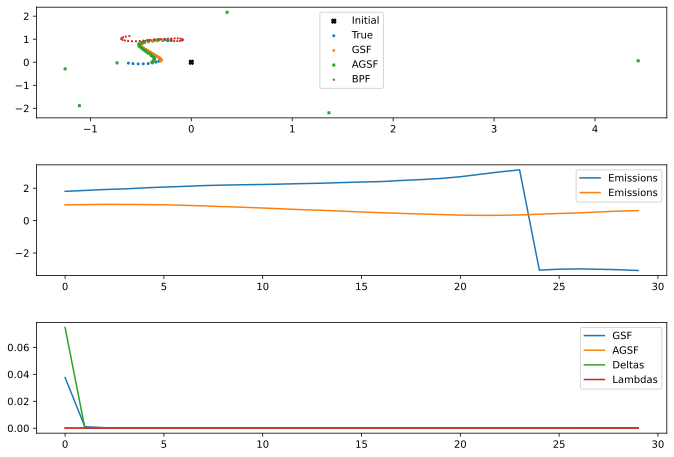

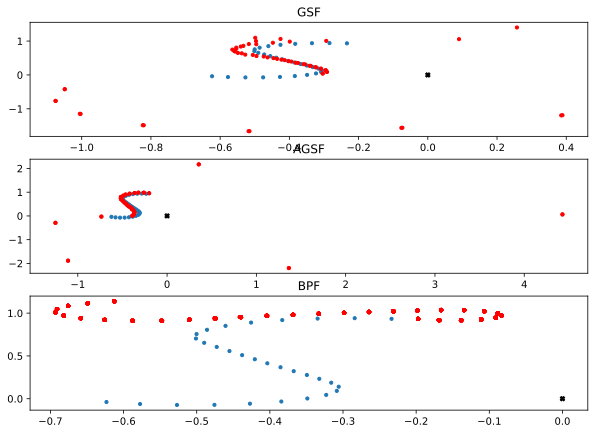

In [ ]:
Nruns = 1
# GSF
M = 2
tin = time.time()
posterior_filtered_gsf = gf.gaussian_sum_filter(params, emissions, 5, 1, inputs)
point_estimate_gsf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_filtered_gsf.means, posterior_filtered_gsf.weights), axis=0)
tout = time.time()
print('Time taken for GSF: ', tout - tin)
print('GSF RMSE:', utils.rmse(point_estimate_gsf, states)) 

next_key = jnp.array([550753349,3769041584], dtype=jnp.uint32)
num_particles = 100
for run in range(Nruns):
    key, next_key = jr.split(next_key)
    # AGSF
    tin = time.time()
    opt_args = (0.8, 0.0001)
    num_components = [M, num_prt1, num_prt2]
    posterior_filtered_agsf, aux_outputs = gf.augmented_gaussian_sum_filter(params, emissions, num_components, rng_key = key, opt_args = opt_args, inputs=inputs)    
    point_estimate_agsf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_filtered_agsf.means, posterior_filtered_agsf.weights), axis=0)
    tout = time.time()
    print('Time taken for AGSF: ', tout - tin)

    # BPF
    tin = time.time()
    ess = 0.5
    posterior_bpf = gf.bootstrap_particle_filter(params_bpf, emissions, num_particles, key, inputs, ess)
    point_estimate_bpf = jnp.sum(jnp.einsum('ijk,ij->ijk', posterior_bpf["particles"], posterior_bpf["weights"]), axis=0)
    tout = time.time()

    print('Time taken for BPF: ', tout - tin)
                                                                         
    print('AGSF RMSE:', utils.rmse(point_estimate_agsf, states))
    print('BPF RMSE:', utils.rmse(point_estimate_bpf, states))

    fig, axes = plt.subplots(3, 1, sharex=False, figsize=(10, 7))
    fig.tight_layout(pad=3.0)
    axes[0].scatter(jnp.array([0]), jnp.array([0]), label = 'Initial', s = 20, marker = 'X', color = 'black')
    axes[0].scatter(states[:,0], states[:,2], label = 'True', s = 4)
    axes[0].scatter(point_estimate_gsf[:,0], point_estimate_gsf[:,2], label = 'GSF', s = 4, marker = 'x')
    axes[0].scatter(point_estimate_agsf[:,0], point_estimate_agsf[:,2], label = 'AGSF', s = 4, marker = 's')
    # axes[0].scatter(point_estimate_agsf_opt[:,0], point_estimate_agsf_opt[:,2], label = 'AGSF-O', s = 4, marker= 'd')
    axes[0].scatter(point_estimate_bpf[:,0], point_estimate_bpf[:,2], label = 'BPF', s = 4, marker = '+')
    axes[0].legend()   

    axes[1].plot(emissions, label = 'Emissions')
    axes[1].legend()

    axes[2].plot(jnp.sum(jnp.trace(posterior_filtered_gsf.covariances, axis1=2, axis2=3), axis=0)/M, label = 'GSF')
    axes[2].plot(jnp.sum(jnp.trace(posterior_filtered_agsf.covariances, axis1=2, axis2=3), axis=0)/M, label = 'AGSF')
    axes[2].plot(jnp.sum(jnp.trace(aux_outputs['Deltas'], axis1=2, axis2=3), axis=1)/5, label = 'Deltas')
    axes[2].plot(jnp.sum(jnp.trace(aux_outputs['Lambdas'], axis1=2, axis2=3), axis=1)/25, label = 'Lambdas')
    axes[2].legend()

    ### Plot 2 (all particles)
    fig2, axes2 = plt.subplots(3, 1, sharex=False, figsize=(10, 7))
    fig.tight_layout(pad=3.0)
    axes2[0].scatter(jnp.array([0]), jnp.array([0]), label = 'Initial', s = 20, marker = 'X', color = 'black')
    axes2[0].scatter(states[:,0], states[:,2], label = 'True', s = 10)
    for m in range(M):
        axes2[0].scatter(posterior_filtered_gsf.means[m, :, 0], posterior_filtered_gsf.means[m, : ,2], label = 'GSF', s = 10, color = 'red')
    axes2[0].title.set_text('GSF')

    axes2[1].scatter(jnp.array([0]), jnp.array([0]), label = 'Initial', s = 20, marker = 'X', color = 'black')
    axes2[1].scatter(states[:,0], states[:,2], label = 'True', s = 10)
    for m in range(M):
        axes2[1].scatter(posterior_filtered_agsf.means[m, :, 0], posterior_filtered_agsf.means[m, : ,2], label = 'AGSF', s = 10,  color = 'red')
    axes2[1].title.set_text('AGSF')

    axes2[2].scatter(jnp.array([0]), jnp.array([0]), label = 'Initial', s = 20, marker = 'X', color = 'black')
    axes2[2].scatter(states[:,0], states[:,2], label = 'True', s = 10)
    for m in range(num_particles):
        axes2[2].scatter(posterior_bpf["particles"][m, :, 0], posterior_bpf["particles"][m, : ,2], label = 'BPF', s = 10, color = 'red')
    axes2[2].title.set_text('BPF')

    plt.show()

## Plots

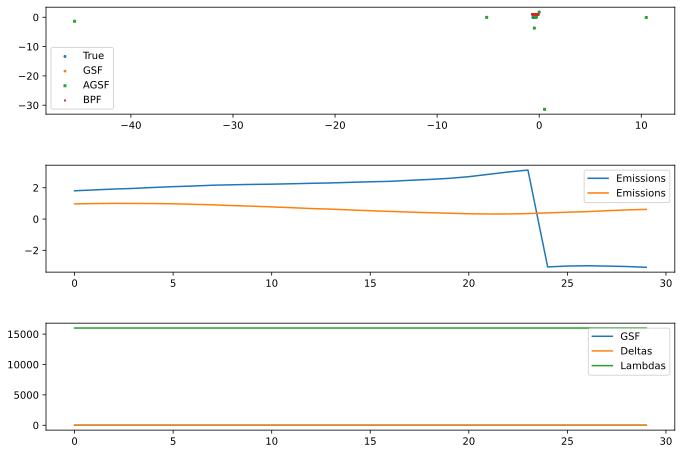

In [ ]:
fig, axes = plt.subplots(3, 1, sharex=False, figsize=(10, 7))
fig.tight_layout(pad=3.0)
axes[0].scatter(states[:,0], states[:,2], label = 'True', s = 4)
axes[0].scatter(point_estimate_gsf[:,0], point_estimate_gsf[:,2], label = 'GSF', s = 4, marker = 'x')
axes[0].scatter(point_estimate_agsf[:,0], point_estimate_agsf[:,2], label = 'AGSF', s = 4, marker = 's')
# axes[0].scatter(point_estimate_agsf_opt[:,0], point_estimate_agsf_opt[:,2], label = 'AGSF-O', s = 4, marker= 'd')
axes[0].scatter(point_estimate_bpf[:,0], point_estimate_bpf[:,2], label = 'BPF', s = 4, marker = '+')
axes[0].legend()   

axes[1].plot(emissions, label = 'Emissions')
axes[1].legend()

axes[2].plot(jnp.sum(jnp.trace(posterior_filtered_gsf.covariances, axis1=2, axis2=3), axis=0)/M, label = 'GSF')
axes[2].plot(jnp.sum(jnp.trace(aux_outputs['Deltas'], axis1=2, axis2=3), axis=1)/5, label = 'Deltas')
axes[2].plot(jnp.sum(jnp.trace(aux_outputs['Lambdas'], axis1=2, axis2=3), axis=1)/25, label = 'Lambdas')
axes[2].legend()

plt.show()

In [ ]:
jnp.allclose(posterior_bpf["particles"][0, :], posterior_bpf["particles"][1, :], atol=1e-1)
print(posterior_bpf["particles"][:, 16])
posterior_bpf["weights"][16]

[[-0.40426555 -0.07167727  0.96820503 -0.02604542]
 [-0.40426555 -0.07167727  0.96820503 -0.02604542]
 [-0.40426555 -0.07167727  0.96820503 -0.02604542]
 [-0.40426555 -0.07167727  0.96820503 -0.02604542]
 [-0.40426555 -0.07167727  0.96820503 -0.02604542]
 [-0.40426555 -0.07167727  0.96820503 -0.02604542]
 [-0.40426555 -0.07167727  0.96820503 -0.02604542]
 [-0.40426555 -0.07167727  0.96820503 -0.02604542]
 [-0.40426555 -0.07167727  0.96820503 -0.02604542]
 [-0.40426555 -0.07167727  0.96820503 -0.02604542]
 [-0.40426555 -0.07167727  0.96820503 -0.02604542]
 [-0.40426555 -0.07167727  0.96820503 -0.02604542]
 [-0.40426555 -0.07167727  0.96820503 -0.02604542]
 [-0.40426555 -0.07167727  0.96820503 -0.02604542]
 [-0.40426555 -0.07167727  0.96820503 -0.02604542]
 [-0.40426555 -0.07167727  0.96820503 -0.02604542]
 [-0.40426555 -0.07167727  0.96820503 -0.02604542]
 [-0.40329722 -0.06974055  0.9681844  -0.02608671]
 [-0.40426555 -0.07167727  0.96820503 -0.02604542]
 [-0.40426555 -0.07167727  0.96

Array([0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01,
       0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01,
       0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01], dtype=float32)

### GSF

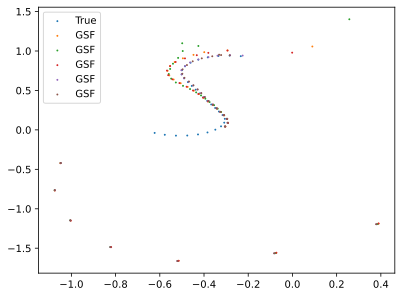

In [ ]:
# num_components = M

# fig, axes = plt.subplots(4, 1, sharex=True, figsize=(10, 7))
# fig.tight_layout(pad=3.0)
# axes[0].plot(states, label="xs")
# leg = ["states"]
# for m in range(M):
#     axes[0].plot(posterior_filtered_gsf.means[m])
#     leg.append("model {}".format(m))
#     axes[0].set_title("filtered means")
# #axes[0].legend(leg)

# if state_dim ==1:
#     for m in range(M):
#         axes[1].plot(posterior_filtered_gsf.covariances[m])
#         axes[1].set_title("filtered covariances")

# for m in range(M):
#     axes[2].plot(posterior_filtered_gsf.weights[m])
#     axes[2].set_title("weights")

# axes[3].plot(states, label="xs")
# leg = ["states", "GSF"]
# axes[3].plot(point_estimate_gsf)
# axes[3].legend(leg)
# axes[3].set_title("point estimate")
# plt.show()

plt.scatter(states[:, 0], states[:,2 ], label = 'True', s = 1)
for m in range(M):
    plt.scatter(posterior_filtered_gsf.means[m, :, 0], posterior_filtered_gsf.means[m, : ,2], label = 'GSF', s = 1)
    plt.legend()   
plt.show()

### AGSF

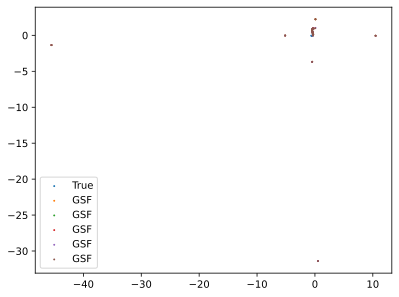

In [ ]:
# fig, axes = plt.subplots(4, 1, sharex=True, figsize=(10, 7))
# fig.tight_layout(pad=3.0)
# axes[0].plot(states, label="xs")
# leg = ["states"]
# for m in range(M):
#     axes[0].plot(posterior_filtered_agsf.means[m])
#     leg.append("model {}".format(m))
#     axes[0].set_title("filtered means")

# #axes[0].legend(leg)

# if state_dim == 1:
#     for m in range(M):
#         axes[1].plot(posterior_filtered_agsf.covariances[m].squeeze())
#         axes[1].set_title("filtered covariances")

# else:
#     for m in range(jnp.prod(num_components)):
#         axes[1].plot(aux_outputs["updated_means"][:,m])
#         axes[1].set_title("updated means")

# for m in range(jnp.prod(jnp.array(num_components))):
#         axes[2].plot(aux_outputs["pre_weights"][:,m])
#         axes[2].set_title("updated pre_weights")

# axes[3].plot(states, label="xs")
# leg = ["states", "AGSF"]
# axes[3].plot(point_estimate_agsf)
# axes[3].legend(leg)
# axes[3].set_title("point estimate")

# plt.show()

## Scatter plots (for target tracking example)
plt.scatter(states[:, 0], states[:,2 ], label = 'True', s = 1)
for m in range(M):
    plt.scatter(posterior_filtered_agsf.means[m, :, 0], posterior_filtered_agsf.means[m, : ,2], label = 'GSF', s = 1)
    plt.legend()   
plt.show()

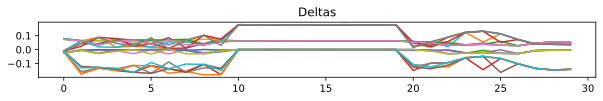

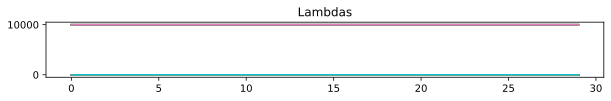

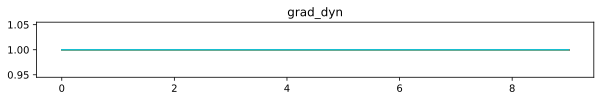

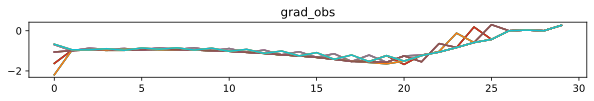

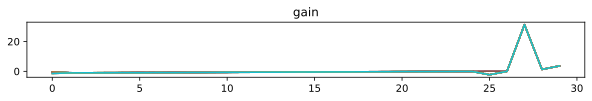

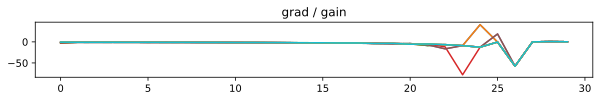

In [ ]:
# plot Deltas
plt.figure(figsize=(10, 1))
for i in range(aux_outputs["Deltas"].shape[1]):
    plt.plot(aux_outputs["Deltas"][:, i, 0])
plt.title('Deltas')
plt.show()

# plot Lambdas
plt.figure(figsize=(10, 1))
for i in range(aux_outputs["Lambdas"].shape[1]):
    plt.plot(aux_outputs["Lambdas"][:, i, 0])
plt.title('Lambdas')
plt.show()

# plot grads_dyn
plt.figure(figsize=(10, 1))
for i in range(aux_outputs["grads_dyn"].shape[0]):
    plt.plot(aux_outputs["grads_dyn"][i, :, 0, 0])
plt.title('grad_dyn')
plt.show()

# plot grads_obs
plt.figure(figsize=(10, 1))
for i in range(aux_outputs["grads_obs"].shape[1]):
    plt.plot(aux_outputs["grads_obs"][:, i, 0, 0])
plt.title('grad_obs')
plt.show()

# plot gain
plt.figure(figsize=(10, 1))
for i in range(aux_outputs["gain"].shape[1]):
    plt.plot(aux_outputs["gain"][:, i, 0, 0])
plt.title('gain')
plt.show()

# plot grads_dyn / gain
plt.figure(figsize=(10, 1))
for i in range(aux_outputs["grads_dyn"].shape[1]):
    plt.plot(aux_outputs["grads_dyn"][:, i, 0, 0] / aux_outputs["gain"][:, i * 3, 0, 0])
plt.title('grad / gain')
plt.show()

### BPF

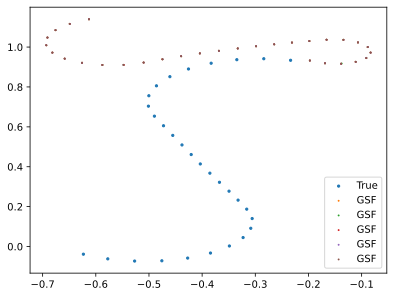

In [ ]:
# fig, axes = plt.subplots(2, 1, sharex=True, figsize=(10, 7))
# fig.tight_layout(pad=3.0)
# axes[0].plot(states, label="xs")
# leg = ["states"]
# for m in range(num_particles):
#     axes[0].plot(posterior_bpf["particles"][m])
#     leg.append("model {}".format(m))
#     axes[0].set_title("particles")

# for m in range(num_particles):
#     axes[1].plot(posterior_bpf["weights"][m])
#     axes[1].set_title("weights")

# plt.show()

## Scatter plots (for target tracking example)
plt.scatter(states[:, 0], states[:,2 ], label = 'True', s = 5)
for m in range(M):
    plt.scatter(posterior_bpf['particles'][m, :, 0], posterior_bpf['particles'][m, : ,2], label = 'GSF', s = 1)
    plt.legend()   
plt.show()